# Laboratorio 4 - SegmentaciÃ³n de imÃ¡genes

## Actividad 1: pipeline de preparaciÃ³n y representaciÃ³n

Aunque las carpetas contienen el conjunto completo de 900 imÃ¡genes de ISIC 2016, este laboratorio utiliza Ãºnicamente las 20 imÃ¡genes indicadas en el enunciado: 15 para ajuste y 5 para prueba. Las mÃ¡scaras de referencia se reservan para evaluar las mÃ¡scaras estimadas; no se utilizan para construir la representaciÃ³n de los pÃ­xeles.

In [1]:

from pathlib import Path

# NumPy representa las imÃ¡genes y las caracterÃ­sticas como arreglos numÃ©ricos.
import numpy as np
import matplotlib.pyplot as plt
# Pillow se utiliza para leer las imÃ¡genes y las mÃ¡scaras.
from PIL import Image
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Se intenta trabajar desde la carpeta del notebook; el segundo caso permite
# ejecutar esta celda desde la raÃ­z del repositorio.
RUTA_LAB = Path.cwd()
if not (RUTA_LAB / "ISBI2016_ISIC_Part1_Training_Data").is_dir():
    RUTA_LAB = RUTA_LAB / "202620" / "Laboratorios" / "L4"
RUTA_IMAGENES = RUTA_LAB / "ISBI2016_ISIC_Part1_Training_Data"
RUTA_MASCARAS = RUTA_LAB / "ISBI2016_ISIC_Part1_Training_GroundTruth"

# Estas 15 imÃ¡genes se usan para explorar y seleccionar la configuraciÃ³n.
IDS_AJUSTE = [
    "ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094",
    "ISIC_0000108", "ISIC_0000114", "ISIC_0000116", "ISIC_0000122",
    "ISIC_0000133", "ISIC_0000137", "ISIC_0000150", "ISIC_0000153",
    "ISIC_0000156", "ISIC_0000157", "ISIC_0000112",
]
# Estas 5 imÃ¡genes se reservan para la evaluaciÃ³n final.
IDS_PRUEBA = [
    "ISIC_0000087", "ISIC_0000105", "ISIC_0000110", "ISIC_0000123",
    "ISIC_0000128",
]
# La lista completa permite verificar las 20 parejas imagen-mÃ¡scara.
IDS_USADOS = IDS_AJUSTE + IDS_PRUEBA




## Carga y preparaciÃ³n de imÃ¡genes y mÃ¡scaras

Los canales RGB y las coordenadas se normalizan a `[0, 1]`. Las mÃ¡scaras se convierten de `0/255` a `0/1`. Si fuera necesario redimensionar una mÃ¡scara, se utiliza vecino mÃ¡s cercano para conservar su naturaleza binaria.

In [2]:
# Construye la ruta de la imagen a partir de su identificador ISIC.
def ruta_imagen(image_id):
    return RUTA_IMAGENES / f"{image_id}.jpg"


# Las mÃ¡scaras tienen el mismo identificador y el sufijo _Segmentation.
def ruta_mascara(image_id):
    return RUTA_MASCARAS / f"{image_id}_Segmentation.png"


def cargar_imagen(image_id):
    """Carga una imagen RGB y devuelve un arreglo uint8 de forma (H, W, 3)."""
    # Se informa explÃ­citamente si falta un archivo seleccionado.
    ruta = ruta_imagen(image_id)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontrÃ³ la imagen: {ruta}")
    # Convertir a RGB garantiza tres canales aunque el archivo tenga otro modo.
    with Image.open(ruta) as imagen:
        return np.asarray(imagen.convert("RGB"))


def cargar_mascara(image_id, tamano=None):
    """Carga, redimensiona opcionalmente y binariza la mÃ¡scara de referencia."""
    ruta = ruta_mascara(image_id)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontrÃ³ la mÃ¡scara: {ruta}")
    
    # L convierte la mÃ¡scara a escala de grises, con un Ãºnico canal.
    with Image.open(ruta) as mascara:
        mascara = mascara.convert("L")
        # El vecino mÃ¡s cercano conserva los valores discretos de la mÃ¡scara.
        if tamano is not None and mascara.size != tamano:
            mascara = mascara.resize(tamano, resample=Image.Resampling.NEAREST)
        valores = np.asarray(mascara)

    # Convierte los valores originales 0/255 en etiquetas binarias 0/1.
    return (valores > 0).astype(np.uint8)


def validar_pares(image_ids):
    """Verifica que cada imagen seleccionada tenga su mÃ¡scara correspondiente."""
    # La mÃ¡scara solo se valida aquÃ­; no participa en la representaciÃ³n de X.
    for image_id in image_ids:
        imagen = cargar_imagen(image_id)
        mascara = cargar_mascara(image_id, tamano=(imagen.shape[1], imagen.shape[0]))
        if imagen.shape[:2] != mascara.shape:
            raise ValueError(f"Dimensiones incompatibles para {image_id}")
        if not np.isin(mascara, [0, 1]).all():
            raise ValueError(f"La mÃ¡scara de {image_id} no es binaria")


validar_pares(IDS_USADOS)
print(f"Pares imagen-mÃ¡scara validados: {len(IDS_USADOS)}")
print(f"ImÃ¡genes de ajuste: {len(IDS_AJUSTE)} | ImÃ¡genes de prueba: {len(IDS_PRUEBA)}")


Pares imagen-mÃ¡scara validados: 20
ImÃ¡genes de ajuste: 15 | ImÃ¡genes de prueba: 5


## RepresentaciÃ³n `[betaÂ·R, betaÂ·G, betaÂ·B, lambdaÂ·x, lambdaÂ·y]`

Cada fila de la matriz representa un pÃ­xel. `x` aumenta de izquierda a derecha y `y` aumenta de arriba hacia abajo. La funciÃ³n conserva por separado la forma `(H, W)` de la imagen para poder reconstruir posteriormente las etiquetas de K-medias como una mÃ¡scara.

In [3]:
def representar_imagen(imagen, beta=1.0, lambda_=1.0):
    """Construye una matriz de caracterÃ­sticas con una fila por pÃ­xel."""
    imagen = np.asarray(imagen)
    if imagen.ndim != 3 or imagen.shape[2] != 3:
        raise ValueError("La imagen debe tener forma (alto, ancho, 3)")
    if beta < 0 or lambda_ < 0 or (beta == 0 and lambda_ == 0):
        raise ValueError("beta y lambda deben ser no negativos y no ambos cero")

    alto, ancho, _ = imagen.shape
    # Los canales RGB pasan de [0, 255] a [0, 1].
    colores = imagen.astype(np.float32) / 255.0
    # x representa columnas y y representa filas, ambas normalizadas a [0, 1].
    x = np.linspace(0.0, 1.0, ancho, dtype=np.float32)
    y = np.linspace(0.0, 1.0, alto, dtype=np.float32)
    coordenada_x, coordenada_y = np.meshgrid(x, y)

    # Cada fila final corresponde a un pÃ­xel y contiene cinco caracterÃ­sticas.
    caracteristicas = np.column_stack([
    # ravel aplana cada canal siguiendo el mismo orden de pÃ­xeles.
        beta * colores[:, :, 0].ravel(),
        beta * colores[:, :, 1].ravel(),
        beta * colores[:, :, 2].ravel(),
        lambda_ * coordenada_x.ravel(),
        lambda_ * coordenada_y.ravel(),
    ])
    return caracteristicas.astype(np.float32)


def crear_pipeline(beta=1.0, lambda_=1.0):
    """Crea el pipeline parametrizable solicitado en la actividad."""
    # FunctionTransformer adapta nuestra funciÃ³n al formato de Pipeline.
    return Pipeline([
    # K-means devuelve etiquetas en una dimensiÃ³n; aquÃ­ recuperamos la imagen.
        (
            "representacion",
            FunctionTransformer(
                lambda imagen: representar_imagen(imagen, beta, lambda_),
                validate=False,
            ),
        ),
    ])


def reconstruir_mascara(etiquetas, forma):
    """Devuelve las etiquetas 1D de los pÃ­xeles con forma (alto, ancho)."""
    alto, ancho = forma
    etiquetas = np.asarray(etiquetas)
    if etiquetas.size != alto * ancho:
        raise ValueError("El nÃºmero de etiquetas no coincide con la imagen")
    return etiquetas.reshape((alto, ancho))


## VerificaciÃ³n con una imagen de ajuste

Se prueba una configuraciÃ³n que combina color y posiciÃ³n. La matriz resultante queda lista para utilizarse como entrada de `KMeans` en la Actividad 2.

In [4]:
# Se verifica una imagen de ajuste sin consultar la mÃ¡scara para construir X.
image_id = IDS_AJUSTE[0]
imagen = cargar_imagen(image_id)
mascara_referencia = cargar_mascara(
    image_id,
    tamano=(imagen.shape[1], imagen.shape[0]),
)

# Esta configuraciÃ³n combina color y posiciÃ³n.
beta = 1.0
lambda_ = 0.5
pipeline = crear_pipeline(beta=beta, lambda_=lambda_)
# X serÃ¡ la entrada de KMeans en la Actividad 2.
X = pipeline.transform(imagen)

assert X.shape == (imagen.shape[0] * imagen.shape[1], 5)
assert mascara_referencia.shape == imagen.shape[:2]
assert np.isin(mascara_referencia, [0, 1]).all()

print(f"Imagen: {image_id}")
print(f"Dimensiones: {imagen.shape[0]} x {imagen.shape[1]}")
print(f"Matriz de representaciÃ³n: {X.shape}")
print(f"Rango de colores normalizados: [{imagen.min() / 255:.3f}, {imagen.max() / 255:.3f}]")
print(f"Valores de la mÃ¡scara: {np.unique(mascara_referencia)}")


Imagen: ISIC_0000085
Dimensiones: 1536 x 2048
Matriz de representaciÃ³n: (3145728, 5)
Rango de colores normalizados: [0.000, 0.902]
Valores de la mÃ¡scara: [0 1]


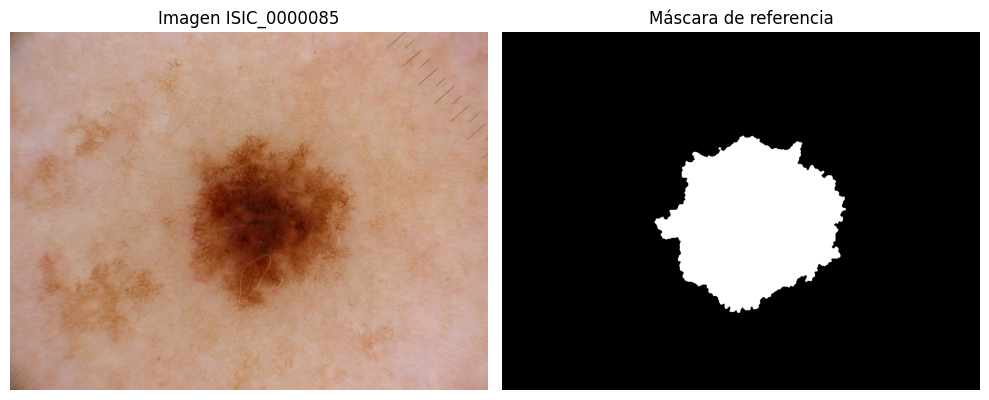

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(imagen)
axes[0].set_title(f"Imagen {image_id}")
axes[1].imshow(mascara_referencia, cmap="gray")
axes[1].set_title("MÃ¡scara de referencia")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## Actividad 2: agrupaciÃ³n y selecciÃ³n de K

Se exploran diez razones distintas entre posiciÃ³n y color. Para cada combinaciÃ³n se entrenan modelos K-medias con `K` entre 2 y 8. El coeficiente de silueta se calcula sobre una muestra reproducible de pÃ­xeles y se utiliza para seleccionar el mejor valor de `K`. Solo se usan las 15 imÃ¡genes de ajuste.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Las parejas (beta, lambda) tienen razones lambda/beta distintas.
# Se incluyen explÃ­citamente los casos de solo color y solo posiciÃ³n.
CONFIGURACIONES = [
    {"beta": 1.0, "lambda_": 0.0, "nombre": "solo_color"},
    {"beta": 1.0, "lambda_": 0.1, "nombre": "lambda_beta_0.1"},
    {"beta": 1.0, "lambda_": 0.25, "nombre": "lambda_beta_0.25"},
    {"beta": 1.0, "lambda_": 0.5, "nombre": "lambda_beta_0.5"},
    {"beta": 1.0, "lambda_": 0.75, "nombre": "lambda_beta_0.75"},
    {"beta": 1.0, "lambda_": 1.0, "nombre": "lambda_beta_1.0"},
    {"beta": 1.0, "lambda_": 2.0, "nombre": "lambda_beta_2.0"},
    {"beta": 1.0, "lambda_": 4.0, "nombre": "lambda_beta_4.0"},
    {"beta": 1.0, "lambda_": 8.0, "nombre": "lambda_beta_8.0"},
    {"beta": 0.0, "lambda_": 1.0, "nombre": "solo_posicion"},
]
VALORES_K = range(2, 9)
TAMANO_MUESTRA_SILUETA = 5000
SEMILLA_MUESTRA = 42
SEMILLA_KMEANS = 42

def indices_muestra(n_elementos, tamano, semilla):
    """Selecciona Ã­ndices sin reemplazo de forma reproducible."""
    rng = np.random.default_rng(semilla)
    cantidad = min(tamano, n_elementos)
    return rng.choice(n_elementos, size=cantidad, replace=False)


def evaluar_kmeans_imagen(image_id, configuracion):
    """Calcula la silueta para K=2,...,8 en una imagen de ajuste."""
    imagen = cargar_imagen(image_id)
    X_imagen = crear_pipeline(
        beta=configuracion["beta"],
        lambda_=configuracion["lambda_"],
    ).transform(imagen)
    indices = indices_muestra(
        len(X_imagen), TAMANO_MUESTRA_SILUETA, SEMILLA_MUESTRA
    )
    X_muestra = X_imagen[indices]
    # Las imÃ¡genes tienen millones de pÃ­xeles; para explorar K se ajusta
    # K-means sobre la misma muestra reproducible usada por la silueta.
    X_entrenamiento = X_muestra
    resultados = []

    for k in VALORES_K:
        modelo = KMeans(
            n_clusters=k,
            random_state=SEMILLA_KMEANS,
            n_init=10,
        )
        # Se ajusta K-medias Ãºnicamente con caracterÃ­sticas, sin mÃ¡scaras.
        etiquetas = modelo.fit_predict(X_entrenamiento)
        silueta = silhouette_score(
            X_muestra,
            etiquetas,
            metric="euclidean",
        )
        resultados.append({
            "imagen": image_id,
            "configuracion": configuracion["nombre"],
            "beta": configuracion["beta"],
            "lambda_": configuracion["lambda_"],
            "K": k,
            "silueta": silueta,
            "muestra_silueta": len(indices),
            "semilla_muestra": SEMILLA_MUESTRA,
        })
    return resultados


In [ ]:
# Se ejecuta el experimento sobre las 15 imÃ¡genes de ajuste.
resultados_actividad_2 = []
for image_id in IDS_AJUSTE:
    for configuracion in CONFIGURACIONES:
        resultados_actividad_2.extend(
            evaluar_kmeans_imagen(image_id, configuracion)
        )

tabla_silueta = pd.DataFrame(resultados_actividad_2)
mejor_k_por_imagen = (
    tabla_silueta.loc[
        tabla_silueta.groupby(["imagen", "configuracion"])["silueta"].idxmax()
    ]
    .sort_values(["configuracion", "imagen"])
    .reset_index(drop=True)
)

promedio_configuraciones = (
    mejor_k_por_imagen.groupby(
        ["configuracion", "beta", "lambda_"]
    )["silueta"]
    .mean()
    .sort_values(ascending=False)
    .rename("silueta_promedio")
    .reset_index()
)

print(f"Filas evaluadas: {len(tabla_silueta)}")
print(f"Muestra por silueta: hasta {TAMANO_MUESTRA_SILUETA} pÃ­xeles")
print(f"Semilla de muestra: {SEMILLA_MUESTRA}")
display(promedio_configuraciones)
